In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

(train_raw, val_raw, test_raw), info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names
num_classes = info.features["label"].num_classes

print("Classes:", class_names)
print("Number of classes:", num_classes)

In [ ]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

def prepare(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    return preprocess_input(image), label

train_ds = train_raw.map(prepare).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.map(prepare).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_raw.map(prepare).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Dataset preprocessing completed!")

Dataset preprocessing completed!


In [ ]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(150, 150, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(50, activation="relu"),
    layers.Dense(20, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │       409,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         1,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,125,463 (57.70 MB)

 Trainable params: 410,775 (1.57 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


c:\Users\Pranav\Desktop\Secret_Wars\DL\Assignments\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 ━━━━━━━━━━━━━━━━━━━━ 71s 864ms/step - accuracy: 0.6594 - loss: 1.6164 - val_accuracy: 0.7187 - val_loss: 0.8648
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 60s 740ms/step - accuracy: 0.8630 - loss: 0.5168 - val_accuracy: 0.7659 - val_loss: 0.8224
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 57s 707ms/step - accuracy: 0.9276 - loss: 0.2448 - val_accuracy: 0.8094 - val_loss: 0.8854
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 56s 691ms/step - accuracy: 0.9591 - loss: 0.1613 - val_accuracy: 0.7967 - val_loss: 0.8462
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 55s 686ms/step - accuracy: 0.9786 - loss: 0.0734 - val_accuracy: 0.8094 - val_loss: 0.8762


In [5]:
base_model.trainable = True

for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5_conv")

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2
)

Epoch 1/2
81/81 ━━━━━━━━━━━━━━━━━━━━ 64s 776ms/step - accuracy: 0.9918 - loss: 0.0331 - val_accuracy: 0.8221 - val_loss: 0.9546
Epoch 2/2
81/81 ━━━━━━━━━━━━━━━━━━━━ 62s 771ms/step - accuracy: 0.9942 - loss: 0.0163 - val_accuracy: 0.8185 - val_loss: 1.0919


In [6]:
loss, accuracy = model.evaluate(test_ds, verbose=0)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Loss: 1.0526
Test Accuracy: 82.91%


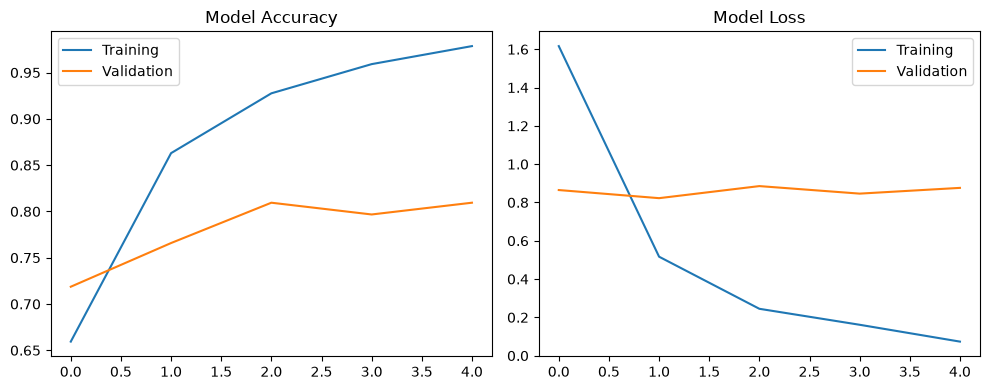

In [7]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
images, labels = next(iter(test_ds))
predictions = model.predict(images[:5], verbose=0)

for i in range(5):
    actual = class_names[int(labels[i].numpy())]
    predicted = class_names[np.argmax(predictions[i])]
    print(f"Actual: {actual} | Predicted: {predicted}")

Actual: daisy | Predicted: roses
Actual: dandelion | Predicted: dandelion
Actual: dandelion | Predicted: sunflowers
Actual: tulips | Predicted: tulips
Actual: tulips | Predicted: tulips


In [ ]:
print('hello')